<a href="https://colab.research.google.com/github/oxanaadry-svg/python_sis_26_2/blob/oxana_silva/aula_oxana_silva_aula14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# -------- Etapa 1 - Configuracao da WeatherAPI --------

# Importando as bibliotecas
import requests
from getpass import getpass

# API utilizada: WeatherAPI
# Documentacao: https://www.weatherapi.com/docs/
# Endpoint: https://api.weatherapi.com/v1/current.json

# Armazenando a chave de forma segura
API_KEY = getpass("Digite sua chave da WeatherAPI: ")

# Definindo a lista de cidades brasileiras
cidades = [
    "Curitiba",
    "Sao Paulo",
    "Rio de Janeiro",
    "Belo Horizonte",
    "Porto Alegre",
    "Salvador",
    "Brasilia",
    "Recife",
    "Fortaleza",
    "Manaus"
]

# Endereco da API
url = "https://api.weatherapi.com/v1/current.json"

# Configurando a consulta
for cidade in cidades:

    parametros = {
        "key": API_KEY,
        "q": cidade,
        "lang": "pt"
    }

    try:
        # Realizando a requisicao
        resposta = requests.get(
            url,
            params=parametros,
            timeout=10
        )

        # Verificando a resposta
        resposta.raise_for_status()

        # Convertendo os dados para JSON
        dados = resposta.json()

        print("Cidade:", dados["location"]["name"])
        print("Temperatura:", dados["current"]["temp_c"], "°C")
        print("Clima:", dados["current"]["condition"]["text"])
        print("-----------------------------")

    except requests.exceptions.RequestException as erro:
        print("Erro na consulta de", cidade, ":", erro)


Digite sua chave da WeatherAPI: ··········
Erro na consulta de Curitiba : 401 Client Error: Unauthorized for url: https://api.weatherapi.com/v1/current.json?key=e411da4287194247954201205262&q=Curitiba&lang=pt
Erro na consulta de Sao Paulo : 401 Client Error: Unauthorized for url: https://api.weatherapi.com/v1/current.json?key=e411da4287194247954201205262&q=Sao+Paulo&lang=pt
Erro na consulta de Rio de Janeiro : 401 Client Error: Unauthorized for url: https://api.weatherapi.com/v1/current.json?key=e411da4287194247954201205262&q=Rio+de+Janeiro&lang=pt
Erro na consulta de Belo Horizonte : 401 Client Error: Unauthorized for url: https://api.weatherapi.com/v1/current.json?key=e411da4287194247954201205262&q=Belo+Horizonte&lang=pt
Erro na consulta de Porto Alegre : 401 Client Error: Unauthorized for url: https://api.weatherapi.com/v1/current.json?key=e411da4287194247954201205262&q=Porto+Alegre&lang=pt
Erro na consulta de Salvador : 401 Client Error: Unauthorized for url: https://api.weatherapi

In [2]:

# -------- Etapa 2 - Consulta e Tratamento de Erros --------

import requests
from getpass import getpass

# API utilizada: WeatherAPI
# Documentacao: https://www.weatherapi.com/docs/

# Armazenando a chave de forma segura
API_KEY = getpass("Digite sua chave da WeatherAPI: ")

# Lista com 10 cidades brasileiras
cidades = [
    "Curitiba",
    "Sao Paulo",
    "Rio de Janeiro",
    "Belo Horizonte",
    "Porto Alegre",
    "Salvador",
    "Brasilia",
    "Recife",
    "Fortaleza",
    "Manaus"
]

# Endpoint da API
url = "https://api.weatherapi.com/v1/current.json"

# Consultando cada cidade
for cidade in cidades:

    print("\nConsultando:", cidade)

    parametros = {
        "key": API_KEY,
        "q": cidade,
        "lang": "pt"
    }

    try:
        # Realizando a requisicao com timeout de 10 segundos
        resposta = requests.get(
            url,
            params=parametros,
            timeout=10
        )

        # Exibindo o codigo de status HTTP
        print("Codigo HTTP:", resposta.status_code)

        # Verificando se ocorreu algum erro HTTP
        resposta.raise_for_status()

        # Convertendo a resposta para JSON
        dados = resposta.json()

        # Exibindo os dados da cidade
        print("Cidade:", dados["location"]["name"])
        print("Temperatura:", dados["current"]["temp_c"], "°C")
        print("Clima:", dados["current"]["condition"]["text"])

    except requests.exceptions.HTTPError as erro:
        print("Erro HTTP:", erro)

        # Mostrando a mensagem de erro da API
        try:
            print("Detalhes:", resposta.json()["error"]["message"])
        except (ValueError, KeyError):
            print("Nao foi possivel obter os detalhes do erro.")

    except requests.exceptions.Timeout:
        print("Erro: Tempo limite de conexao excedido.")

    except requests.exceptions.ConnectionError:
        print("Erro: Falha na conexao com a internet.")

    except requests.exceptions.RequestException as erro:
        print("Erro na requisicao:", erro)

    except (ValueError, KeyError) as erro:
        print("Erro ao processar os dados recebidos:", erro)

    print("-----------------------------")

print("\nConsultas finalizadas!")


Digite sua chave da WeatherAPI: ··········

Consultando: Curitiba
Codigo HTTP: 200
Cidade: Curitiba
Temperatura: 17.0 °C
Clima: Chuva irregular nas proximidades
-----------------------------

Consultando: Sao Paulo
Codigo HTTP: 200
Cidade: Sao Paulo
Temperatura: 19.3 °C
Clima: Chuva irregular nas proximidades
-----------------------------

Consultando: Rio de Janeiro
Codigo HTTP: 200
Cidade: Rio De Janeiro
Temperatura: 23.5 °C
Clima: Chuva passageira fraca
-----------------------------

Consultando: Belo Horizonte
Codigo HTTP: 200
Cidade: Belo Horizonte
Temperatura: 23.2 °C
Clima: Chuva passageira moderada ou forte
-----------------------------

Consultando: Porto Alegre
Codigo HTTP: 200
Cidade: Porto Alegre
Temperatura: 24.7 °C
Clima: Ensolarado
-----------------------------

Consultando: Salvador
Codigo HTTP: 200
Cidade: Salvador
Temperatura: 27.5 °C
Clima: Parcialmente nublado
-----------------------------

Consultando: Brasilia
Codigo HTTP: 200
Cidade: Brasilia
Temperatura: 24.4 °C

In [3]:

# -------- Etapa 3 - Conversao e Armazenamento dos Dados --------

import requests
from getpass import getpass

# API utilizada: WeatherAPI
# Documentacao: https://www.weatherapi.com/docs/

# Armazenando a chave de forma segura
API_KEY = getpass("Digite sua chave da WeatherAPI: ")

# Lista com 10 cidades brasileiras
cidades = [
    "Curitiba",
    "Sao Paulo",
    "Rio de Janeiro",
    "Belo Horizonte",
    "Porto Alegre",
    "Salvador",
    "Brasilia",
    "Recife",
    "Fortaleza",
    "Manaus"
]

# Endereco da API
url = "https://api.weatherapi.com/v1/current.json"

# Lista para armazenar os resultados
resultados = []

# Consultando cada cidade
for cidade in cidades:

    parametros = {
        "key": API_KEY,
        "q": cidade,
        "lang": "pt"
    }

    try:
        # Realizando a requisicao
        resposta = requests.get(
            url,
            params=parametros,
            timeout=10
        )

        # Verificando o codigo HTTP
        print("Cidade:", cidade)
        print("Codigo HTTP:", resposta.status_code)

        resposta.raise_for_status()

        # Convertendo a resposta para dicionario Python
        dados = resposta.json()

        # Inspecionando as chaves principais
        print("Chaves principais:", dados.keys())

        # Armazenando os dados na lista
        resultados.append(dados)

    except requests.exceptions.HTTPError as erro:
        print("Erro HTTP:", erro)

    except requests.exceptions.Timeout:
        print("Tempo limite de conexao excedido.")

    except requests.exceptions.ConnectionError:
        print("Falha na conexao com a internet.")

    except requests.exceptions.RequestException as erro:
        print("Erro na requisicao:", erro)

    print("-----------------------------")


# Exibindo os resultados coletados
print("\nRESUMO DOS DADOS COLETADOS")

for registro in resultados:

    nome = registro["location"]["name"]
    temperatura = registro["current"]["temp_c"]
    condicao = registro["current"]["condition"]["text"]

    print("\nCidade:", nome)
    print("Temperatura atual:", temperatura, "°C")
    print("Condicao do tempo:", condicao)

    print("-----------------------------")

# Mostrando a quantidade de resultados
print("\nTotal de cidades consultadas com sucesso:", len(resultados))


Digite sua chave da WeatherAPI: ··········
Cidade: Curitiba
Codigo HTTP: 200
Chaves principais: dict_keys(['location', 'current'])
-----------------------------
Cidade: Sao Paulo
Codigo HTTP: 200
Chaves principais: dict_keys(['location', 'current'])
-----------------------------
Cidade: Rio de Janeiro
Codigo HTTP: 200
Chaves principais: dict_keys(['location', 'current'])
-----------------------------
Cidade: Belo Horizonte
Codigo HTTP: 200
Chaves principais: dict_keys(['location', 'current'])
-----------------------------
Cidade: Porto Alegre
Codigo HTTP: 200
Chaves principais: dict_keys(['location', 'current'])
-----------------------------
Cidade: Salvador
Codigo HTTP: 200
Chaves principais: dict_keys(['location', 'current'])
-----------------------------
Cidade: Brasilia
Codigo HTTP: 200
Chaves principais: dict_keys(['location', 'current'])
-----------------------------
Cidade: Recife
Codigo HTTP: 200
Chaves principais: dict_keys(['location', 'current'])
----------------------------

In [4]:

# -------- Etapa 1 - Conversao para DataFrame --------

import pandas as pd

# Utilizando a lista de resultados da atividade anterior

# Convertendo os dados JSON em DataFrame
dados = pd.json_normalize(resultados)

# Selecionando apenas as colunas importantes
dados = dados[
    [
        "location.name",
        "current.temp_c",
        "current.condition.text",
        "current.humidity",
        "current.wind_kph"
    ]
]

# Renomeando as colunas para portugues
dados = dados.rename(columns={
    "location.name": "Cidade",
    "current.temp_c": "Temperatura",
    "current.condition.text": "Condicao do Tempo",
    "current.humidity": "Umidade",
    "current.wind_kph": "Velocidade do Vento"
})

# Exibindo o DataFrame
print("Tabela de dados meteorologicos:")
print(dados)

# Mostrando as primeiras linhas
print("\nPrimeiros registros:")
print(dados.head())

# Mostrando informacoes da tabela
print("\nInformacoes do DataFrame:")
dados.info()


Tabela de dados meteorologicos:
           Cidade  Temperatura                   Condicao do Tempo  Umidade  \
0        Curitiba         17.0    Chuva irregular nas proximidades       87   
1       Sao Paulo         19.3    Chuva irregular nas proximidades       84   
2  Rio De Janeiro         23.5              Chuva passageira fraca       84   
3  Belo Horizonte         23.2  Chuva passageira moderada ou forte       88   
4    Porto Alegre         24.7                          Ensolarado       42   
5        Salvador         27.5                Parcialmente nublado       72   
6        Brasilia         24.4              Chuva passageira fraca       79   
7          Recife         28.1                          Ensolarado       63   
8       Fortaleza         31.9                Parcialmente nublado       46   
9          Manaus         35.5    Chuva irregular nas proximidades       41   

   Velocidade do Vento  
0                 13.7  
1                 15.8  
2                 10.8 

In [5]:

# -------- Etapa 2 - Tratamento e Tipagem dos Dados --------

import pandas as pd

# Criando o DataFrame a partir dos resultados da API
dados = pd.json_normalize(resultados)

# Selecionando as colunas importantes
dados = dados[
    [
        "location.name",
        "current.temp_c",
        "current.condition.text",
        "current.humidity",
        "current.wind_kph",
        "location.localtime"
    ]
]

# Renomeando as colunas
dados = dados.rename(columns={
    "location.name": "Cidade",
    "current.temp_c": "Temperatura",
    "current.condition.text": "Condicao do Tempo",
    "current.humidity": "Umidade",
    "current.wind_kph": "Velocidade do Vento",
    "location.localtime": "Data e Hora"
})

# Removendo registros duplicados
dados = dados.drop_duplicates()

# Convertendo a data e hora
dados["Data e Hora"] = pd.to_datetime(
    dados["Data e Hora"],
    errors="coerce"
)

# Convertendo os valores para numeros
colunas_numericas = [
    "Temperatura",
    "Umidade",
    "Velocidade do Vento"
]

for coluna in colunas_numericas:
    dados[coluna] = pd.to_numeric(
        dados[coluna],
        errors="coerce"
    )

# Exibindo a tabela tratada
print("Dados apos o tratamento:")
print(dados)

# Exibindo os tipos de dados
print("\nTipos de dados:")
print(dados.dtypes)

# Exibindo o resumo estatistico
print("\nResumo estatistico:")
print(dados.describe())

print("\nTratamento dos dados concluido!")


Dados apos o tratamento:
           Cidade  Temperatura                   Condicao do Tempo  Umidade  \
0        Curitiba         17.0    Chuva irregular nas proximidades       87   
1       Sao Paulo         19.3    Chuva irregular nas proximidades       84   
2  Rio De Janeiro         23.5              Chuva passageira fraca       84   
3  Belo Horizonte         23.2  Chuva passageira moderada ou forte       88   
4    Porto Alegre         24.7                          Ensolarado       42   
5        Salvador         27.5                Parcialmente nublado       72   
6        Brasilia         24.4              Chuva passageira fraca       79   
7          Recife         28.1                          Ensolarado       63   
8       Fortaleza         31.9                Parcialmente nublado       46   
9          Manaus         35.5    Chuva irregular nas proximidades       41   

   Velocidade do Vento         Data e Hora  
0                 13.7 2026-11-26 17:14:00  
1              

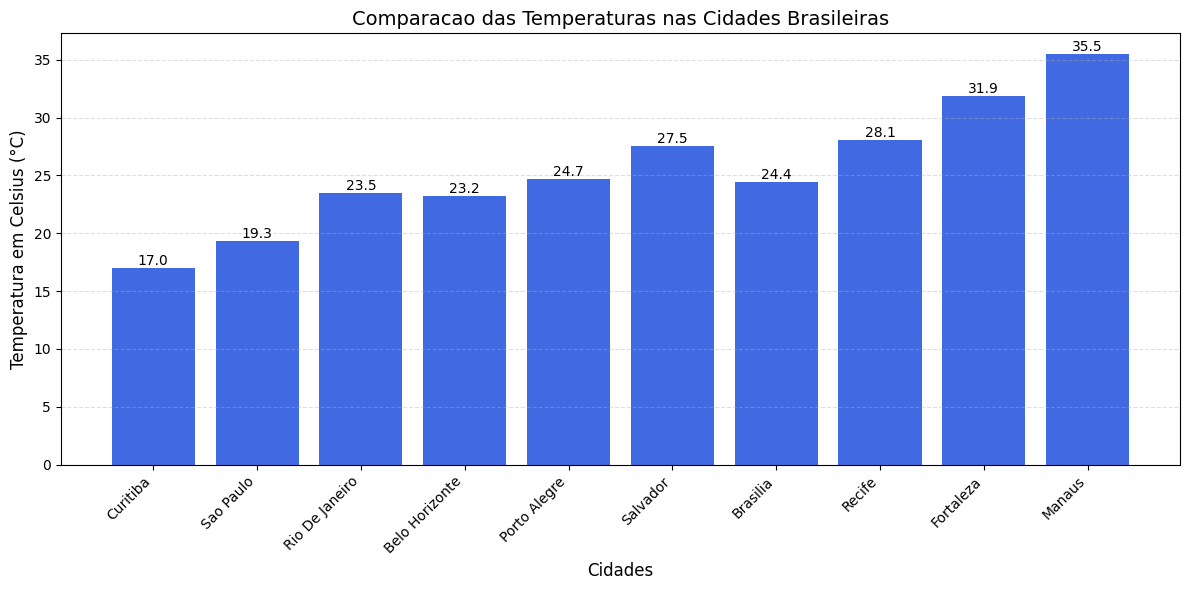


Maior temperatura:
Manaus - 35.5 °C

Menor temperatura:
Curitiba - 17.0 °C

Arquivos exportados com sucesso!


In [6]:

# -------- Etapa 3 - Grafico e Exportacao dos Dados --------

import pandas as pd
import matplotlib.pyplot as plt

# Utilizando o DataFrame tratado da etapa anterior

# Criando o grafico de temperaturas
plt.figure(figsize=(12, 6))

plt.bar(
    dados["Cidade"],
    dados["Temperatura"],
    color="royalblue"
)

# Adicionando titulo e nomes dos eixos
plt.title(
    "Comparacao das Temperaturas nas Cidades Brasileiras",
    fontsize=14
)

plt.xlabel("Cidades", fontsize=12)
plt.ylabel("Temperatura em Celsius (°C)", fontsize=12)

# Ajustando os nomes das cidades
plt.xticks(rotation=45, ha="right")

# Adicionando valores nas barras
for i, valor in enumerate(dados["Temperatura"]):
    plt.text(
        i,
        valor,
        round(valor, 1),
        ha="center",
        va="bottom"
    )

# Adicionando grade
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Ajustando o grafico
plt.tight_layout()

# Exibindo o grafico
plt.show()


# Identificando a maior e menor temperatura
maior = dados.loc[dados["Temperatura"].idxmax()]
menor = dados.loc[dados["Temperatura"].idxmin()]

print("\nMaior temperatura:")
print(maior["Cidade"], "-", maior["Temperatura"], "°C")

print("\nMenor temperatura:")
print(menor["Cidade"], "-", menor["Temperatura"], "°C")


# Exportando o DataFrame para CSV
dados.to_csv(
    "relatorio_meteorologico.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportando o DataFrame para Excel
dados.to_excel(
    "relatorio_meteorologico.xlsx",
    index=False
)

print("\nArquivos exportados com sucesso!")
